In [15]:
import pandas as pd

df = pd.read_csv("filtered_modelling.csv")
df.drop(columns=["Timestamp"], inplace=True, errors="ignore")

In [16]:
df.isna().sum()

Are you 21 years of age or older?                                               0
Have you had a completed night out within the past 30 days?                     0
Are you currently under the influence taking this survey                        0
Please enter your age                                                           2
Which best describes your gender?                                               2
What is your height?                                                           16
Which best describes your current education status?                             2
How financially comfortable do you currently feel?                              2
Which SF Neighborhood do you live in?                                           2
Where did you receive this survey?                                              2
What day of the week was this night out?                                        2
How planned was this night out?                                                 2
At approximately

In [9]:
df.dtypes

Are you 21 years of age or older?                                   object
Have you had a completed night out within the past 30 days?         object
Are you currently under the influence taking this survey            object
Please enter your age                                              float64
Which best describes your gender?                                   object
What is your height?                                                object
Which best describes your current education status?                 object
How financially comfortable do you currently feel?                 float64
Which SF Neighborhood do you live in?                               object
Where did you receive this survey?                                  object
What day of the week was this night out?                            object
How planned was this night out?                                     object
At approximately what time did your night out begin?                object
Where did you spend most 

In [17]:
df.columns = [ 

    # Screening Questions (3)
    "twenty_one", # Are you 21 years of age or older?  
    "recent_night_out", #Have you had a completed night out within the past 30 days?  
    "under_influence", # Are you currently under the influence taking this survey  

    # Demographics (7)
    "exact_age", # Please enter your age
    "gender", # Which best describes your gender?
    "height", #What is your height?
    "education_status", # Which best describes your current education status?
    "financial_security", #How financially comfortable do you currently feel?
    "sf_neighborhood", #Which SF Neighborhood do you live in?
    "survey_source", #Where did you receive this survey?

    # Most Recent Night Out (16)
    "day_of_week_nightout",#What day of the week was this night out?
    "planning_level", #How planned was this night out?
    "time_began", #At approximately what time did your night out begin?
    "primary_location", #Where did you spend most of the night?
    "pregrame", # Did you pregame?
    "group_size", #How many people were in your group, including yourself?
    "primary_companion", #Who did you primarily spend the night with?
    'transportation_method', #What was your primary mode of transportation?
    'hours_out', #Approximately how many hours did your night out last?
    'time_end', #At approximately what time did your night end?
    'money_spent', #Approximately how much money did you personally spend (USD)?
    'alcohol_consumed', #Did you consume any alcohol during this night out?
    'non_alcoholic_substance', #Did you consume substances other than alcohol?
    'end_of_night_state', #Did you end the night...
    'locations_visited', #How many different venues or locations did you visit?
    'eat_after', #At the end of the night, did you have something to eat?

    #Target Variable (1)
    'y', # Overall, how enjoyable was this night out?

        # IDEAL NIGHT OUT (16)
    "ideal_day_of_week",            # What day of the week would this night out take place?
    "ideal_planning_level",         # How planned would this night out be?
    "ideal_time_began",             # What time would you want your night out to begin?
    "ideal_hours_out",              # How long would your night out to be (in hours)?
    "ideal_time_end",               # What time would your night end?
    "ideal_primary_location",       # Where would you like to spend most of the night?
    "ideal_pregame",                # Would a pregame be a necessity for your night out?
    "ideal_group_size",             # How many people is ideal for the perfect night out?
    "ideal_primary_companion",      # What type of people would be ideal?
    "ideal_money_needed",           # Approximately how much money do you feel is needed for the night out (USD)?
    "ideal_transportation_method",  # What would be the best way to get around during your night out?
    "ideal_alcohol_consumed",       # Would you need to consume alcohol (in any capacity)?
    "ideal_non_alcoholic_substance",# Would you need to consume any other substances other than alcohol?
    "ideal_end_of_night_state",      # Does your perfect night end with you being...
    "ideal_locations_visited",      # How many locations would you like to visit?
    "ideal_eat_after"               # At the end of the night, would you want to have something to eat?
]

In [18]:
df.isna().sum()

twenty_one                        0
recent_night_out                  0
under_influence                   0
exact_age                         2
gender                            2
height                           16
education_status                  2
financial_security                2
sf_neighborhood                   2
survey_source                     2
day_of_week_nightout              2
planning_level                    2
time_began                        2
primary_location                  2
pregrame                          2
group_size                        2
primary_companion                 2
transportation_method             2
hours_out                         2
time_end                          2
money_spent                       2
alcohol_consumed                  2
non_alcoholic_substance           2
end_of_night_state                2
locations_visited                 2
eat_after                         2
y                                 2
ideal_day_of_week           

In [19]:
# EDA: Keep all columns
df_eda = df.copy()

# Modeling: Keep everything up to and including y
df_model = df.loc[:, :"y"].copy()

In [20]:
df_eda.to_csv("df_eda.csv", index=False)
df_model.to_csv("df_filtered_model.csv", index=False)

In [21]:
print("Original:", df.shape)
print("EDA:", df_eda.shape)
print("Modeling:", df_model.shape)

Original: (107, 43)
EDA: (107, 43)
Modeling: (107, 27)


In [24]:
df = pd.read_csv('df_filtered_model.csv')

df.shape

(107, 27)

In [25]:
df.isna().sum()

twenty_one                  0
recent_night_out            0
under_influence             0
exact_age                   2
gender                      2
height                     16
education_status            2
financial_security          2
sf_neighborhood             2
survey_source               2
day_of_week_nightout        2
planning_level              2
time_began                  2
primary_location            2
pregrame                    2
group_size                  2
primary_companion           2
transportation_method       2
hours_out                   2
time_end                    2
money_spent                 2
alcohol_consumed            2
non_alcoholic_substance     2
end_of_night_state          2
locations_visited           2
eat_after                   2
y                           2
dtype: int64

count    105.000000
mean      22.666667
std        5.149060
min       18.000000
25%       20.000000
50%       21.000000
75%       25.000000
max       49.000000
Name: exact_age, dtype: float64
21.0


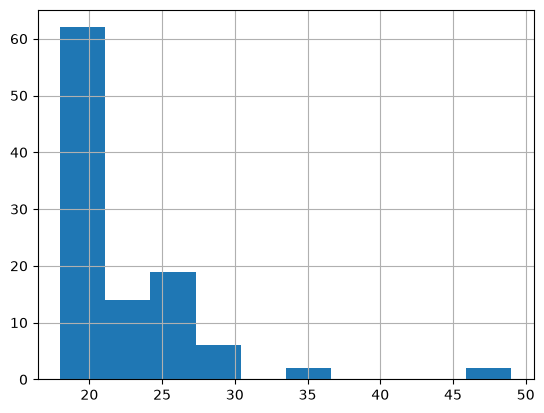

In [33]:
df.exact_age.hist()
print(df.exact_age.describe())
print(df.exact_age.median())

In [35]:
df.exact_age.isna().sum()

np.int64(2)

In [36]:
#changes made: fill missing 2 ages with the median age as mean is skewed right. And also the first column tells us they are at least 21

df["exact_age"] = df["exact_age"].fillna(df["exact_age"].median())
df.isna().sum()

twenty_one                  0
recent_night_out            0
under_influence             0
exact_age                   0
gender                      2
height                     16
education_status            2
financial_security          2
sf_neighborhood             2
survey_source               2
day_of_week_nightout        2
planning_level              2
time_began                  2
primary_location            2
pregrame                    2
group_size                  2
primary_companion           2
transportation_method       2
hours_out                   2
time_end                    2
money_spent                 2
alcohol_consumed            2
non_alcoholic_substance     2
end_of_night_state          2
locations_visited           2
eat_after                   2
y                           2
dtype: int64

In [39]:
df.gender.value_counts()

gender
Female         50
Male           47
Non-Binary      6
Trans man       1
genderfluid     1
Name: count, dtype: int64

In [42]:
df.groupby("gender")["y"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

,count,mean,median,std,min,max
gender,,,,,,
Female,50,8.180000,8.0,1.452514,5.0,10.0
Male,47,7.744681,8.0,1.972287,3.0,10.0
Non-Binary,6,7.833333,8.0,1.169045,6.0,9.0
Trans man,1,10.000000,10.0,NaN,10.0,10.0
genderfluid,1,4.000000,4.0,NaN,4.0,4.0


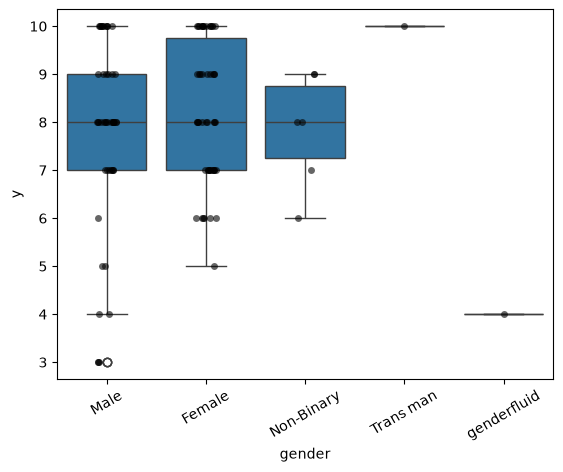

In [44]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="gender", y="y")

sns.stripplot(
    data=df,
    x="gender",
    y="y",
    color="black",
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=30)
plt.show()

In [45]:
df['gender_binned'] = df['gender'].replace({
    'Non-Binary':'Other',
    'Trans man' : 'Other',
    'genderfluid': 'Other'})
    

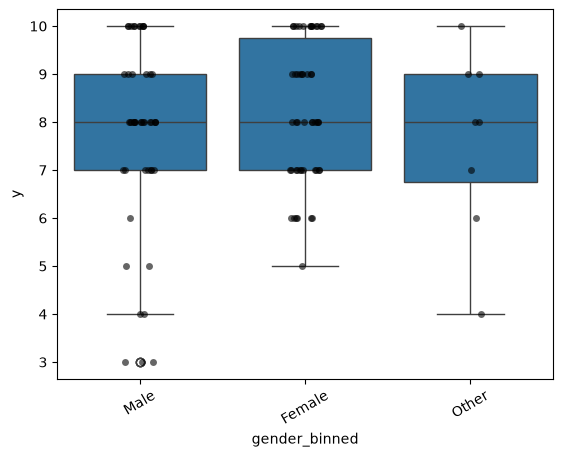

In [53]:
sns.boxplot(data=df, x="gender_binned", y="y")

sns.stripplot(
    data=df,
    x="gender_binned",
    y="y",
    color="black",
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=30)
plt.show()

In [52]:
df.gender_binned.value_counts()

gender_binned
Female    50
Male      47
Other      8
Name: count, dtype: int64

In [54]:
df.groupby("gender_binned")["y"].agg([
    "count",
    "mean",
    "median",
    "std"
])

,count,mean,median,std
gender_binned,,,,
Female,50,8.180000,8.0,1.452514
Male,47,7.744681,8.0,1.972287
Other,8,7.625000,8.0,1.922610


In [56]:
df.isna().sum()

twenty_one                  0
recent_night_out            0
under_influence             0
exact_age                   0
gender                      2
height                     16
education_status            2
financial_security          2
sf_neighborhood             2
survey_source               2
day_of_week_nightout        2
planning_level              2
time_began                  2
primary_location            2
pregrame                    2
group_size                  2
primary_companion           2
transportation_method       2
hours_out                   2
time_end                    2
money_spent                 2
alcohol_consumed            2
non_alcoholic_substance     2
end_of_night_state          2
locations_visited           2
eat_after                   2
y                           2
gender_binned               2
dtype: int64

In [61]:
pd.set_option('display.max_columns', None)

In [63]:
df.query("gender_binned.isna() or gender.isna()")

# These two rows are literally the source of so many missing values, remove these two.

,twenty_one,recent_night_out,under_influence,exact_age,gender,height,education_status,financial_security,sf_neighborhood,survey_source,day_of_week_nightout,planning_level,time_began,primary_location,pregrame,group_size,primary_companion,transportation_method,hours_out,time_end,money_spent,alcohol_consumed,non_alcoholic_substance,end_of_night_state,locations_visited,eat_after,y,gender_binned
0,Yes,No,No,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Yes,No,No,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [64]:
# Remove respondents who did not provide an enjoyment rating
df.dropna(subset=["y"], inplace=True)

# Reset row indices
df.reset_index(drop=True, inplace=True)

In [65]:
df.isna().sum()

twenty_one                  0
recent_night_out            0
under_influence             0
exact_age                   0
gender                      0
height                     14
education_status            0
financial_security          0
sf_neighborhood             0
survey_source               0
day_of_week_nightout        0
planning_level              0
time_began                  0
primary_location            0
pregrame                    0
group_size                  0
primary_companion           0
transportation_method       0
hours_out                   0
time_end                    0
money_spent                 0
alcohol_consumed            0
non_alcoholic_substance     0
end_of_night_state          0
locations_visited           0
eat_after                   0
y                           0
gender_binned               0
dtype: int64

In [67]:
df.shape

(105, 28)

In [68]:
df.gender.unique()

array(['Male', 'Female', 'Non-Binary', 'Trans man', 'genderfluid'],
      dtype=object)

In [69]:
df.drop(columns='gender', inplace = True)

In [79]:
df.height.value_counts()

height
5’6                                             7
5'10                                            5
5’3                                             4
5’5                                             4
5’4”                                            4
5'2                                             3
5’9                                             3
5’8                                             3
5’11                                            2
5’7                                             2
5'6"                                            2
5’4                                             2
6’0                                             2
5'3                                             2
5'5                                             2
5’9”                                            2
5’5”                                            2
5’2                                             2
5-10                                            1
164cm                                      

In [80]:
import numpy as np

height_map = {
    # 4 feet
    "4'10\"": 58,

    # 5 feet
    "5’0": 60,

    "5’1": 61,
    "5'1": 61,

    "5'2": 62,
    "5’2": 62,
    "5’2”": 62,
    "5’2 in": 62,

    "5’3": 63,
    "5'3": 63,

    "5’4": 64,
    "5’4”": 64,
    "5'4": 64,
    "5'4\"": 64,

    "5’5": 65,
    "5'5": 65,
    "5’5”": 65,
    "5.5": 65,  # Assumed 5 feet 5 inches

    "5’6": 66,
    "5'6": 66,
    "5'6\"": 66,
    "5’6”": 66,
    "5ft  6in": 66,

    "5’7": 67,
    "5'7": 67,
    "5'7\"": 67,
    "5’7”": 67,

    "5’8": 68,
    "5'8": 68,
    "5 8'": 68,
    "5.8": 68,  # Assumed 5 feet 8 inches

    "5’9": 69,
    "5’9”": 69,
    "5'9\"": 69,

    "5'10": 70,
    "5’10": 70,
    "5'10\"": 70,
    "5-10": 70,

    "5’11": 71,

    # 6 feet
    "6’0": 72,
    "6'0": 72,
    "6'": 72,
    "6 ft": 72,
    "6ft": 72,
    "6 feet": 72,
    "6’ 0.05”": 72.05,

    "6’1”": 73,
    "6' 1\"": 73,
    "6’1 or 6’3 with the shoes i have on rn lol 🐗": 73,

    "6'2": 74,
    "6'3\"": 75,
    "6’4": 76,
    "6'5": 77,
    "6’5": 77,

    # Metric measurements
    "164cm": round(164 / 2.54, 2),

    # Invalid responses
    "3 apples tall": np.nan
}

# Map original heights to numerical inches
df["height_inches"] = df["height"].map(height_map)

In [87]:
# Compare original and converted heights
df[["height", "height_inches"]].to_string()

'                                           height  height_inches\n0                                            5’11          71.00\n1                                             6’0          72.00\n2                                             NaN            NaN\n3                                             6’4          76.00\n4                                           164cm          64.57\n5                                            5’5”          65.00\n6                                            5’6”          66.00\n7                                             5’3          63.00\n8                                             5.8          68.00\n9                                             5’6          66.00\n10                                            NaN            NaN\n11                                            5’8          68.00\n12                                            5’8          68.00\n13                                         6 feet          72.00\n14       

In [88]:
# Check for any responses that failed to map
df.loc[
    df["height_inches"].isna() & df["height"].notna(),
    "height"
].value_counts()

height
3 apples tall    1
Name: count, dtype: int64

In [91]:
# Check missing values
print(df["height_inches"].isna().sum())

# Summary statistics
df["height_inches"].describe()
print(df["height_inches"].median())
df["height_inches"].describe()

15
66.0


count    90.000000
mean     67.095778
std       4.014835
min      58.000000
25%      64.000000
50%      66.000000
75%      70.000000
max      77.000000
Name: height_inches, dtype: float64

In [86]:
df["height_inches"] = df["height"].str.strip().map(height_map)

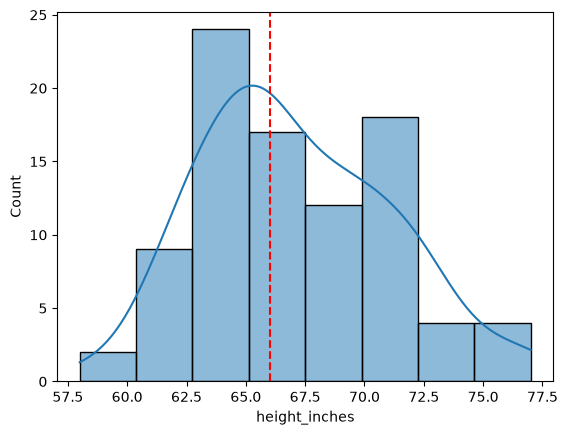

In [92]:
sns.histplot(data=df, x="height_inches", kde=True)
plt.axvline(df.height_inches.median(), color="red", linestyle="--")
plt.show()

#actual

In [93]:
df.height_inches.isna().sum()

np.int64(15)

In [104]:
corr = df.corr(numeric_only=True)['y'].sort_values(ascending = False)
corr

y                     1.000000
financial_security    0.280230
hours_out             0.214168
exact_age             0.121508
money_spent           0.067393
height_inches         0.023528
Name: y, dtype: float64

<Axes: xlabel='height_inches', ylabel='y'>

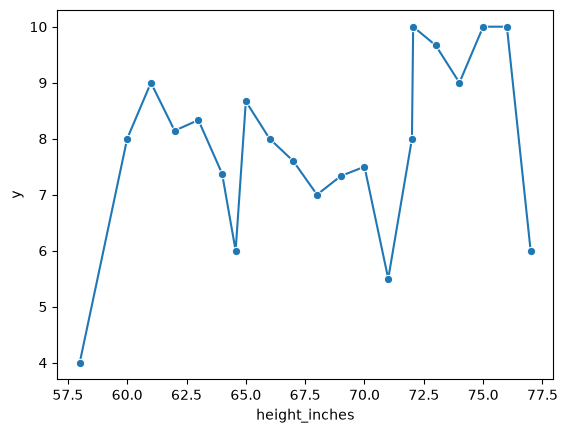

In [114]:
sns.lineplot(data=df, x="height_inches", y="y", errorbar=None, marker ='o')

In [115]:
# fill median

df.height_inches.fillna(df.height_inches.median(), inplace = True)

In [117]:
df.isna().sum()

twenty_one                  0
recent_night_out            0
under_influence             0
exact_age                   0
height                     14
education_status            0
financial_security          0
sf_neighborhood             0
survey_source               0
day_of_week_nightout        0
planning_level              0
time_began                  0
primary_location            0
pregrame                    0
group_size                  0
primary_companion           0
transportation_method       0
hours_out                   0
time_end                    0
money_spent                 0
alcohol_consumed            0
non_alcoholic_substance     0
end_of_night_state          0
locations_visited           0
eat_after                   0
y                           0
gender_binned               0
height_inches               0
dtype: int64

In [118]:
df.drop(columns = {'height'}, inplace=True)

In [119]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
education_status           0
financial_security         0
sf_neighborhood            0
survey_source              0
day_of_week_nightout       0
planning_level             0
time_began                 0
primary_location           0
pregrame                   0
group_size                 0
primary_companion          0
transportation_method      0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
end_of_night_state         0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
dtype: int64

In [121]:
df.education_status.value_counts()

education_status
Currently pursuing an associate or bachelor’s degree                   71
Completed an associate or bachelor’s degree, not currently enrolled    16
Completed a graduate or professional degree, not currently enrolled     8
Currently pursuing a graduate or professional degree                    6
High school graduate or equivalent, not enrolled in college             4
Name: count, dtype: int64

In [123]:
df.education_status.value_counts()

education_status
Currently pursuing an associate or bachelor’s degree                   71
Completed an associate or bachelor’s degree, not currently enrolled    16
Completed a graduate or professional degree, not currently enrolled     8
Currently pursuing a graduate or professional degree                    6
High school graduate or equivalent, not enrolled in college             4
Name: count, dtype: int64

In [122]:
education_map = {
    'High school graduate or equivalent, not enrolled in college' : 1,
    'Currently pursuing an associate or bachelor’s degree' : 2,
    'Completed an associate or bachelor’s degree, not currently enrolled' : 3,
    'Currently pursuing a graduate or professional degree' : 4,
    'Completed a graduate or professional degree, not currently enrolled': 5
}

df['education_ranking'] = df['education_status'].map(education_map)
df['education_ranking'].value_counts()

education_ranking
2    71
3    16
5     8
4     6
1     4
Name: count, dtype: int64

In [124]:
df = df.drop(columns='education_status')

In [125]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
sf_neighborhood            0
survey_source              0
day_of_week_nightout       0
planning_level             0
time_began                 0
primary_location           0
pregrame                   0
group_size                 0
primary_companion          0
transportation_method      0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
end_of_night_state         0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
dtype: int64

financial_security
3.0    43
4.0    27
2.0    19
5.0    11
1.0     5
Name: count, dtype: int64


<Axes: >

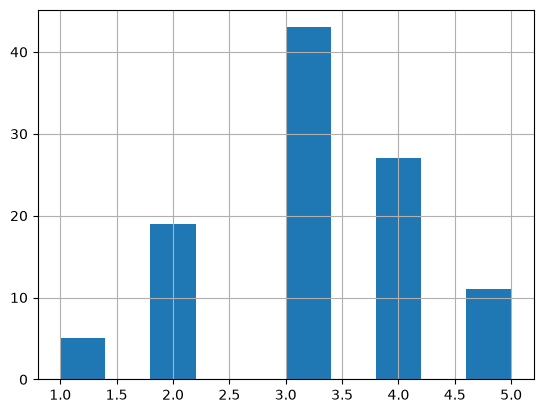

In [129]:
print(df.financial_security.value_counts())
df.financial_security.hist()

# Map
"Other": "Other",
"Inner Richmond": "Inner Richmond",
"Lone Mountain": "Lone Mountain",
"Sunset": "Sunset",
"other": "Other",
"Ingleside": "Ingleside",
"Lone Mountain": "Lone Mountain",
"Inner Richmond": "Inner Richmond",
"Sunset": "Sunset",
"Park Merced": "Parkmerced",
"Japantown": "Japantown",
"Misson Bay": "Mission Bay",
"Mission District": "Mission District",
"on usf campus": "Lone Mountain",
"Middle Richmond": "Central Richmond",
"I live on campus.": "Lone Mountain",
"Richmond district": "Richmond",
"Balboa": "Balboa",
"NOPA (on campus)": "NoPa",
"Miraloma": "Miraloma Park",
"Portola": "Portola",
"On campus at USF": "Lone Mountain",
"Wherever USF is": "Lone Mountain",
"gillson hall": "Lone Mountain",
"Panhandle": "Panhandle",
"Richmond (live on campus)": "Lone Mountain",
"Laurel Heights": "Laurel Heights",
"Outer Sunset": "Outer Sunset",
"USF campus/Laural heights": "Laurel Heights",
"I live at the University of San Francisco - which is considered to be inner Richmond.": "Inner Richmond",
"Richmond": "Richmond",
"Other! LA babey!!!": "Other",
"Fillmore": "Fillmore",
"Outer Sunset district": "Outer Sunset",
"Anza Vista": "Anza Vista",
"Uni dorm": "Lone Mountain",
"lone mountain": "Lone Mountain",
"other": "Other",
"Mission": "Mission District",
"Lower Pac": "Lower Pacific Heights",
"On campus": "Lone Mountain",
"Lower Pac Heights": "Lower Pacific Heights",
"Sa Jose": "Other",
"Other": "Other",
"Daly City": "Other",
"Forest Hill": "Forest Hill",
"Presidio": "Presidio",
"SOMA": "SoMa",
"Irving": "Sunset",
"Golden Gate": "Golden Gate",
"Lone Mountain North Residence Hall": "Lone Mountain",
"Fulton street, USF": "Lone Mountain",
"Lowe Pacific Heights": "Lower Pacific Heights",
"South San Francisco": "Other",
"Other - (Carson)": "Other",
"Excelsior": "Excelsior",
"On USF campus": "Lone Mountain",

In [132]:
df.sf_neighborhood.value_counts()
#nominal data
# To do:
# relabel then pd.get_dummies


sf_neighborhood
Other                                                                                    25
Inner Richmond                                                                            8
Lone Mountain                                                                             6
Sunset                                                                                    5
other                                                                                     4
Ingleside                                                                                 3
Lone Mountain                                                                             2
Inner Richmond                                                                            2
Bayview                                                                                   1
Sunset                                                                                    1
Park Merced                                                     

In [133]:
df["sf_neighborhood"] = df["sf_neighborhood"].str.strip()

df["sf_neighborhood"] = (
    df["sf_neighborhood"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

In [134]:
for value in df["sf_neighborhood"].unique():
    print(repr(value))

'Balboa'
'Sunset'
'Anza Vista'
'Uni dorm'
'lone mountain'
'Inner Richmond'
'Other'
'other'
'Mission'
'Lower Pac'
'On campus'
'Ingleside'
'Lower Pac Heights'
'Sa Jose'
'Outer Sunset district'
'Daly City'
'Lone Mountain'
'Presidio'
'SOMA'
'Irving'
'Golden Gate'
'Lone Mountain North Residence Hall'
'Fulton street, USF'
'Lowe Pacific Heights'
'South San Francisco'
'Other - (Carson)'
'Other! LA babey!!!'
'Excelsior'
'Forest Hill'
'Fillmore'
'Portola'
'Richmond'
'Bayview'
'Park Merced'
'Japantown'
'Misson Bay'
'Mission District'
'on usf campus'
'Middle Richmond'
'I live on campus.'
'Richmond district'
'Miraloma'
'NOPA (on campus)'
'On campus at USF'
'Wherever USF is'
'gillson hall'
'Panhandle'
'Richmond (live on campus)'
'Laurel Heights'
'Outer Sunset'
'USF campus/Laural heights'
'I live at the University of San Francisco - which is considered to be inner Richmond.'
'On USF campus'


In [135]:
neighborhood_map = {
    "other": "Other",
    "inner richmond": "Inner Richmond",
    "lone mountain": "Lone Mountain",
    "sunset": "Sunset",
    "ingleside": "Ingleside",
    "bayview": "Bayview",
    "park merced": "Parkmerced",
    "japantown": "Japantown",
    "misson bay": "Mission Bay",
    "mission district": "Mission District",
    "mission": "Mission District",
    "on usf campus": "Lone Mountain",
    "middle richmond": "Central Richmond",
    "i live on campus.": "Lone Mountain",
    "richmond district": "Richmond",
    "balboa": "Balboa",
    "nopa (on campus)": "NoPa",
    "miraloma": "Miraloma Park",
    "portola": "Portola",
    "on campus at usf": "Lone Mountain",
    "wherever usf is": "Lone Mountain",
    "gillson hall": "Lone Mountain",
    "panhandle": "Panhandle",
    "richmond (live on campus)": "Lone Mountain",
    "laurel heights": "Laurel Heights",
    "outer sunset": "Outer Sunset",
    "usf campus/laural heights": "Laurel Heights",
    "i live at the university of san francisco - which is considered to be inner richmond.": "Inner Richmond",
    "richmond": "Richmond",
    "other! la babey!!!": "Other",
    "fillmore": "Fillmore",
    "outer sunset district": "Outer Sunset",
    "anza vista": "Anza Vista",
    "uni dorm": "Lone Mountain",
    "lower pac": "Lower Pacific Heights",
    "on campus": "Lone Mountain",
    "lower pac heights": "Lower Pacific Heights",
    "sa jose": "Other",
    "daly city": "Other",
    "forest hill": "Forest Hill",
    "presidio": "Presidio",
    "soma": "SoMa",
    "irving": "Sunset",
    "golden gate": "Golden Gate",
    "lone mountain north residence hall": "Lone Mountain",
    "fulton street, usf": "Lone Mountain",
    "lowe pacific heights": "Lower Pacific Heights",
    "south san francisco": "Other",
    "other - (carson)": "Other",
    "excelsior": "Excelsior"
}



In [136]:
df["neighborhood"] = (
    df["sf_neighborhood"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.lower()
    .map(neighborhood_map)
)

In [142]:
print(df.neighborhood.value_counts(dropna=False))
df.neighborhood.value_counts(dropna=False).sum()

neighborhood
Other                    36
Lone Mountain            20
Inner Richmond           11
Sunset                    7
Lower Pacific Heights     3
Ingleside                 3
Laurel Heights            2
Outer Sunset              2
Mission District          2
Richmond                  2
Bayview                   1
NoPa                      1
Miraloma Park             1
Central Richmond          1
Panhandle                 1
Mission Bay               1
Japantown                 1
Parkmerced                1
Balboa                    1
Portola                   1
Fillmore                  1
Forest Hill               1
Golden Gate               1
SoMa                      1
Presidio                  1
Anza Vista                1
Excelsior                 1
Name: count, dtype: int64


np.int64(105)

In [143]:
df[['sf_neighborhood', 'neighborhood']].to_string()

'                                                                           sf_neighborhood           neighborhood\n0                                                                                   Balboa                 Balboa\n1                                                                                   Sunset                 Sunset\n2                                                                               Anza Vista             Anza Vista\n3                                                                                 Uni dorm          Lone Mountain\n4                                                                            lone mountain          Lone Mountain\n5                                                                           Inner Richmond         Inner Richmond\n6                                                                                    Other                  Other\n7                                                                              

In [144]:
df.drop(columns={"sf_neighborhood"}, inplace = True)

In [145]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
survey_source              0
day_of_week_nightout       0
planning_level             0
time_began                 0
primary_location           0
pregrame                   0
group_size                 0
primary_companion          0
transportation_method      0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
end_of_night_state         0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
neighborhood               0
dtype: int64

In [146]:
df.survey_source.value_counts()

survey_source
USF / University                          61
Social Media                              16
At a bar or nightlife venue                8
Friend                                     4
friend                                     2
Friend/former co worker                    1
Personal Reference                         1
From Lucas                                 1
Lucas ❤️                                   1
USF student                                1
Lucas  sent it to me                       1
Friend from USF                            1
work                                       1
coworker who is friend of survey giver     1
Cecilia                                    1
Through a link from a friend               1
Referral                                   1
Peter from canvas                          1
Calculus II Professor                      1
Name: count, dtype: int64

In [147]:
df.drop(columns = 'survey_source', inplace = True)

In [148]:
df.day_of_week_nightout.value_counts()

day_of_week_nightout
Saturday     43
Friday       37
Thursday      9
Wednesday     7
Tuesday       5
Monday        3
Sunday        1
Name: count, dtype: int64

In [149]:
# pd. get_dummies because 
# mapping would imply 1 = monday,... 7 = sunday, sunday irl is 1 day away
# but model will learn that it's 7 units away'


df.planning_level.value_counts()

planning_level
Somewhat planned           41
Planned well in advance    32
Somewhat spontaneous       21
Completely spontaneous     11
Name: count, dtype: int64

In [150]:
df.planning_level.nunique()

4

In [151]:
#map there is natural ordering

plan_map = {
    'Completely spontaneous': 1,
    'Somewhat spontaneous': 2,
    'Somewhat planned' : 3,
    'Planned well in advance':4
    

}

df["planning_level"] = df["planning_level"].map(plan_map)

In [154]:
df.planning_level.value_counts() ==df.planning_level.value_counts()

planning_level
3    True
4    True
2    True
1    True
Name: count, dtype: bool

In [155]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
day_of_week_nightout       0
planning_level             0
time_began                 0
primary_location           0
pregrame                   0
group_size                 0
primary_companion          0
transportation_method      0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
end_of_night_state         0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
neighborhood               0
dtype: int64

In [156]:
df.time_began.value_counts()

time_began
9:00:00 PM     16
8:00:00 PM     15
10:00:00 PM    14
7:00:00 PM      8
6:00:00 PM      7
5:00:00 PM      6
6:30:00 PM      4
11:00:00 PM     3
8:30:00 PM      3
11:30:00 PM     3
1:00:00 AM      2
4:00:00 PM      2
11:20:00 PM     2
12:00:00 PM     2
10:30:00 PM     2
8:00:00 AM      1
3:30:00 PM      1
10:45:00 PM     1
7:30:00 PM      1
12:00:00 AM     1
2:16:00 AM      1
7:50:00 PM      1
5:30:00 PM      1
2:30:00 PM      1
10:15:00 PM     1
6:18:00 PM      1
6:45:00 AM      1
9:45:00 PM      1
10:40:00 PM     1
9:30:00 PM      1
4:30:00 PM      1
Name: count, dtype: int64

In [161]:
df['primary_location'].value_counts()
'''
Unique categories: given there's  alot of 1's, we should bucket them

'Bar or pub': "bar_or_pub",
'Someone else’s home': 'home',
'Restaurant': 'restaurant',
'Nightclub':'club',
'My home':'home',
'Mall': 'mall',
'beach/ cave near the beach':'beach',
'Castro St. Block Party': 'party'
'Concert': 'concert'
'gym/restaurant': 'restaurant' #just go w/ restarurant since it's already a category
'Frats': 'party'
'Driving':'driving',
'Table Tennis club':'hobby_club',
'Concert Venue': 'concert'
'USF campus':'school',
'Castro Block Party':'party',
'Theater - we went to a concert':'concert',
'castro street party': 'party',
'Reserved event room':'hobby_club',
'hotel':'home',
'Movies and restaurant': 'restaurant',
'Its like a shopping commerce area so thered like bars and restaurants and places and things': 'mall',
'University':'school',
'Dowtown SF': 'outside',
'Dance ballroom':'hobby_club',
'Party Bus': 'party',
'Outside in general': outside',
'Halfmoon bay': 'outside',
'Cafe':'restaurant', # just label it, close enough
'Outside': 'outside',

'''



primary_location
Bar or pub                                                                                     31
Someone else’s home                                                                            17
Restaurant                                                                                     14
Nightclub                                                                                      12
My home                                                                                         4
Mall                                                                                            2
beach/ cave near the beach                                                                      1
Castro St. Block Party                                                                          1
Concert                                                                                         1
gym/restaurant                                                                                  1
Fra

In [162]:
location_map = {
    'Bar or pub': 'bar_or_pub',
    'Someone else’s home': 'home',
    'Restaurant': 'restaurant',
    'Nightclub': 'club',
    'My home': 'home',
    'Mall': 'mall',
    'beach/ cave near the beach': 'beach',
    'Castro St. Block Party': 'party',
    'Concert': 'concert',
    'gym/restaurant': 'restaurant', # Just go with restaurant since it's already a category
    'Frats': 'party',
    'Driving': 'driving',
    'Table Tennis club': 'hobby_club',
    'Concert Venue': 'concert',
    'USF campus': 'school',
    'Castro Block Party': 'party',
    'Theater - we went to a concert': 'concert',
    'castro street party': 'party',
    'Reserved event room': 'hobby_club',
    'hotel': 'home',
    'Movies and restaurant': 'restaurant',
    'Its like a shopping commerce area so thered like bars and restaurants and places and things': 'mall',
    'Museum': 'museum', # Missing from original mapping
    'University': 'school',
    'Dowtown SF': 'outside',
    'Dance ballroom': 'hobby_club',
    'Party Bus': 'party',
    'Outside in general': 'outside',
    'Halfmoon bay': 'outside',
    'Cafe': 'restaurant', # Just label it, close enough
    'Outside': 'outside'
}

# 13 distinct locations, coefficients of model may be diluted, bucket further
df["location_binned"] = df["primary_location"].str.strip().map(location_map)

# Number of distinct categories
df["location_binned"].nunique()

13

In [163]:
df.location_binned.value_counts()
# bin further for larger coefficients

location_binned
bar_or_pub    31
home          22
restaurant    17
club          12
party          5
outside        4
hobby_club     3
mall           3
concert        3
school         2
museum         1
beach          1
driving        1
Name: count, dtype: int64

categories

night life: bar_or_pub, club,party

home:home

dining:restaurant

entertainment:hobby_club, concert, museum

outdoors: outside, mall, school, beach, driving



In [164]:
# Further bin locations to reduce sparse categories,
# preserve observations and reduce the number of coefficients.

location_bins = {
    # Nightlife and social events
    "bar_or_pub": "nightlife",
    "club": "nightlife",
    "party": "nightlife",

    # Residential
    "home": "home",

    # Dining
    "restaurant": "dining",

    # Entertainment and recreational activities
    "hobby_club": "entertainment",
    "mall": "entertainment",
    "concert": "entertainment",
    "museum": "entertainment",

    # Outdoor and miscellaneous locations
    "outside": "outdoor_other",
    "school": "outdoor_other",
    "beach": "outdoor_other",
    "driving": "outdoor_other"
}

df["location_binned"] = df["location_binned"].replace(location_bins)

df.location_binned.value_counts()

location_binned
nightlife        48
home             22
dining           17
entertainment    10
outdoor_other     8
Name: count, dtype: int64

In [165]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
day_of_week_nightout       0
planning_level             0
time_began                 0
primary_location           0
pregrame                   0
group_size                 0
primary_companion          0
transportation_method      0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
end_of_night_state         0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
neighborhood               0
location_binned            0
dtype: int64

In [166]:
df.drop(columns={'primary_location'}, inplace=True)

In [169]:
# Replace '8+' with 8, save it back, and convert the whole column to integers
df['group_size'] = df['group_size'].replace('8+', 8).astype(int)


<Axes: >

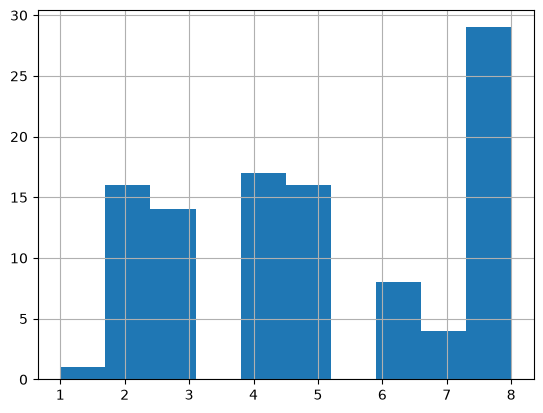

In [170]:
df.group_size.hist()

In [172]:
df.primary_companion.value_counts()

primary_companion
Friends                                                          57
Friends, Romantic partner or date                                13
Romantic partner or date                                          7
Friends, Coworkers or acquaintances                               7
Friends, Mixed group / Other                                      6
Family                                                            3
Friends, Romantic partner or date, Mixed group / Other            2
Alone                                                             2
Alone, Friends                                                    2
Friends, Family                                                   1
Romantic partner or date, Family                                  1
Friends, Romantic partner or date, Coworkers or acquaintances     1
Coworkers or acquaintances                                        1
Friends, Romantic partner or date, Family                         1
Coworkers or acquaintances, Mi

In [173]:
# Multi-hot encoding with further pooling of sparse categories.
# Respondents can belong to multiple categories simultaneously.

companion_map = {
    "with_friends": ["Friends"],
    "with_partner": ["Romantic partner or date"],
    "with_other": [
        "Family",
        "Coworkers or acquaintances",
        "Mixed group / Other"
    ],
    "with_alone": ["Alone"]
}

for new, original in companion_map.items():
    df[new] = (
        df["primary_companion"]
        .str.contains("|".join(original), regex=True, na=False)
        .astype(int)
    )

# Count observations in each new column
df[list(companion_map.keys())].sum()

with_friends    90
with_partner    25
with_other      24
with_alone       4
dtype: int64

In [176]:
df.drop(columns='primary_companion', inplace = True)

In [174]:
df[list(companion_map.keys())].sum().sum()

np.int64(143)

In [175]:
90+25+24+4

143

In [178]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
day_of_week_nightout       0
planning_level             0
time_began                 0
pregrame                   0
group_size                 0
transportation_method      0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
end_of_night_state         0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
neighborhood               0
location_binned            0
with_friends               0
with_partner               0
with_other                 0
with_alone                 0
dtype: int64

In [180]:
df.transportation_method.value_counts()
# evenly split, so we should keep as is and rename

transportation_method
Ride-share / Taxi           33
Public transportation       28
Walking                     20
Riding with someone else    13
Driving myself              11
Name: count, dtype: int64

In [181]:
33 + 13 + 11 #ppl who used cars

57

In [182]:
20 + 28

48

In [184]:
# given ~50/50 split, cats: public trans vs private trans

trans_map = {
    "Ride-share / Taxi": "car",
    "Public transportation": "non_car",
    "Walking": "non_car",
    "Riding with someone else": "car",
    "Driving myself": "car"
}

df['transportation_binned'] = df['transportation_method'].str.strip().map(trans_map)

df.transportation_binned.value_counts()
    

AttributeError: 'DataFrame' object has no attribute 'transportion_binned'

In [185]:
df.transportation_binned.value_counts()

transportation_binned
car        57
non_car    48
Name: count, dtype: int64

In [188]:
df.drop(columns = {'transportation_method'}, inplace = True)

In [189]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
day_of_week_nightout       0
planning_level             0
time_began                 0
pregrame                   0
group_size                 0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
end_of_night_state         0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
neighborhood               0
location_binned            0
with_friends               0
with_partner               0
with_other                 0
with_alone                 0
transportation_binned      0
dtype: int64

In [196]:
df.end_of_night_state.value_counts()

end_of_night_state
Sober                  42
Tipsy                  20
Drunk                  19
Drunk and Non-Sober    11
Tispy and Non-Sober     9
Non-Sober               4
Name: count, dtype: int64

In [197]:
# Bin end-of-night states to reduce sparse categories.
# Combine responses involving reported non-sobriety.

sobriety_map = {
    "Sober": "sober",
    "Tipsy": "tipsy",
    "Drunk": "drunk",
    "Drunk and Non-Sober": "non_sober",
    "Tispy and Non-Sober": "non_sober",
    "Non-Sober": "non_sober"
}

df["sobriety_binned"] = df["end_of_night_state"].str.strip().map(sobriety_map)

df.sobriety_binned.value_counts()

sobriety_binned
sober        42
non_sober    24
tipsy        20
drunk        19
Name: count, dtype: int64

In [198]:
df.drop(columns = {'end_of_night_state'}, inplace = True)

In [202]:
print(df.locations_visited.value_counts())

df['locations_visited'] = df['locations_visited'].replace('6+', 6).astype(int)

locations_visited
2     34
1     34
3     29
4      6
6+     1
5      1
Name: count, dtype: int64


In [203]:
print(df.locations_visited.value_counts())

locations_visited
2    34
1    34
3    29
4     6
6     1
5     1
Name: count, dtype: int64


In [205]:
df.eat_after.value_counts()

eat_after
No                                             29
Yes, Late night restaurant                     29
Yes, Something at home (you made something)    27
Yes, Food delivery (e.g. Doordash)             20
Name: count, dtype: int64

In [207]:
df.groupby("eat_after")["y"].agg([
    "count",
    "mean",
    "median",
    "std",
    "min",
    "max"
])

,count,mean,median,std,min,max
eat_after,,,,,,
No,29,7.724138,8.0,1.306483,4.0,10.0
"Yes, Food delivery (e.g. Doordash)",20,8.000000,8.0,1.891811,4.0,10.0
"Yes, Late night restaurant",29,8.034483,8.0,1.636258,3.0,10.0
"Yes, Something at home (you made something)",27,8.037037,9.0,2.156947,3.0,10.0


In [208]:
import statsmodels.formula.api as smf

# Create binary predictor
df["ate_after_binned"] = df["eat_after"].str.startswith("Yes").astype(int)

# Reduced model
reduced = smf.ols("y ~ ate_after_binned", data=df).fit()

# Full model
full = smf.ols("y ~ C(eat_after)", data=df).fit()

# Nested F-test
full.compare_f_test(reduced)

(np.float64(0.0030599579685620013),
 np.float64(0.9969448113506277),
 np.float64(2.0))

In [209]:
df.ate_after_binned

0      1
1      1
2      0
3      1
4      1
      ..
100    1
101    1
102    1
103    0
104    1
Name: ate_after_binned, Length: 105, dtype: int64

In [210]:
df.ate_after_binned.value_counts()

ate_after_binned
1    76
0    29
Name: count, dtype: int64

In [216]:
df.drop(columns={'eat_after'}, inplace=True)

In [212]:
df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
day_of_week_nightout       0
planning_level             0
time_began                 0
pregrame                   0
group_size                 0
hours_out                  0
time_end                   0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
locations_visited          0
eat_after                  0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
neighborhood               0
location_binned            0
with_friends               0
with_partner               0
with_other                 0
with_alone                 0
transportation_binned      0
sobriety_binned            0
ate_after_binned           0
dtype: int64

In [217]:
temp_df = df.drop(columns={'time_began', 'time_end'}).copy()

In [219]:
temp_df.isna().sum()

twenty_one                 0
recent_night_out           0
under_influence            0
exact_age                  0
financial_security         0
day_of_week_nightout       0
planning_level             0
pregrame                   0
group_size                 0
hours_out                  0
money_spent                0
alcohol_consumed           0
non_alcoholic_substance    0
locations_visited          0
y                          0
gender_binned              0
height_inches              0
education_ranking          0
neighborhood               0
location_binned            0
with_friends               0
with_partner               0
with_other                 0
with_alone                 0
transportation_binned      0
sobriety_binned            0
ate_after_binned           0
dtype: int64

In [221]:
'twenty_one' in temp_df

True

In [215]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.linear_model import (
    LinearRegression,
    RidgeCV,
    LassoCV,
    ElasticNetCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Separate predictors and target
X = temp_df.drop(columns=["y"])
y = temp_df["y"].astype(float)

# Encode remaining categorical variables
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Verify dimensions and missing values
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values:", X.isna().sum().sum())
print("Matrix rank:", np.linalg.matrix_rank(X))

X shape: (105, 65)
y shape: (105,)
Missing values: 0
Matrix rank: 64


In [222]:
# Add intercept
X_ols = sm.add_constant(X)

# Fit OLS
ols_model = sm.OLS(y, X_ols).fit()

print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.758
Model:                            OLS   Adj. R-squared:                  0.370
Method:                 Least Squares   F-statistic:                     1.952
Date:                Fri, 27 Nov 2026   Prob (F-statistic):             0.0126
Time:                        19:20:06   Log-Likelihood:                -132.06
No. Observations:                 105   AIC:                             394.1
Df Residuals:                      40   BIC:                             566.6
Df Model:                          64                                         
Covariance Type:            nonrobust                                         
                                                            coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------

/var/folders/cx/qk1b249j0fs0kqqcml92l_t40000gn/T/ipykernel_37165/310916994.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ols_model = sm.OLS(y, X_ols).fit()


In [223]:
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Standardize predictors
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [224]:
alphas = np.logspace(-4, 4, 100)

# OLS
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

# Ridge
ridge = RidgeCV(alphas=alphas, cv=5)
ridge.fit(X_train_scaled, y_train)

# Lasso
lasso = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=100000
)
lasso.fit(X_train_scaled, y_train)

# Elastic Net
elastic = ElasticNetCV(
    alphas=alphas,
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0],
    cv=5,
    max_iter=100000
)
elastic.fit(X_train_scaled, y_train)

,"l1_ratio l1_ratio: float or list of float, default=0.5Float between 0 and 1 passed to ElasticNet (scaling betweenl1 and l2 penalties). For ``l1_ratio = 0``the penalty is an L2 penalty. For ``l1_ratio = 1`` it is an L1 penalty.For ``0 < l1_ratio < 1``, the penalty is a combination of L1 and L2This parameter can be a list, in which case the differentvalues are tested by cross-validation and the one giving the bestprediction score is used. Note that a good choice of list ofvalues for l1_ratio is often to put more values close to 1(i.e. Lasso) and less close to 0 (i.e. Ridge), as in ``[.1, .5, .7,.9, .95, .99, 1]``.","[0.1, 0.3, ...]"
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path, used for each l1_ratio.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",array([1.0000...00000000e+04])
,"max_iter max_iter: int, default=1000The maximum number of iterations.",100000
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"verbose verbose: bool or int, default=0Amount of verbosity.",0
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [225]:
models = {
    "OLS": ols,
    "Ridge": ridge,
    "Lasso": lasso,
    "Elastic Net": elastic
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Train R2": model.score(X_train_scaled, y_train),
        "Test R2": r2_score(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "Nonzero Coefficients": np.count_nonzero(model.coef_)
    })

results_df = pd.DataFrame(results)

results_df.sort_values("RMSE")

,Model,Train R2,Test R2,MSE,RMSE,Nonzero Coefficients
0,OLS,0.835743,0.012548,4.196111,2.048441,65
1,Ridge,0.643781,-0.102041,4.683051,2.164036,61
3,Elastic Net,0.686389,-0.129576,4.800058,2.190903,33
2,Lasso,0.699330,-0.141075,4.848921,2.202027,33


In [228]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "OLS": ols.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "Elastic Net": elastic.coef_
})

coefficients.sort_values(by = 'OLS', ascending = False)

,Feature,OLS,Ridge,Lasso,Elastic Net
1,financial_security,0.847795,0.278828,0.417774,0.397325
48,neighborhood_Other,0.705219,0.040535,0.000000,0.000000
22,day_of_week_nightout_Wednesday,0.663270,0.166113,0.290024,0.264439
46,neighborhood_Mission District,0.624179,0.163191,0.223894,0.211464
20,day_of_week_nightout_Thursday,0.602307,0.098225,0.180926,0.162862
...,...,...,...,...,...
25,non_alcoholic_substance_Yes,-0.269531,-0.025203,-0.000000,-0.000000
27,"eat_after_Yes, Late night restaurant",-0.301808,-0.037979,-0.000000,-0.000000
51,neighborhood_Parkmerced,-0.341367,-0.207551,-0.305768,-0.289070
59,location_binned_nightlife,-0.448704,-0.222099,-0.198497,-0.213713


In [229]:
coefficients[coefficients["Lasso"] == 0]

,Feature,OLS,Ridge,Lasso,Elastic Net
0,exact_age,1.078452e-01,0.063508,0.0,0.000000
2,planning_level,2.973876e-02,-0.001644,-0.0,-0.000000
3,group_size,4.060573e-02,-0.063331,-0.0,-0.000000
5,money_spent,-1.460300e-01,0.028544,0.0,0.000000
6,locations_visited,-2.066632e-01,0.072073,0.0,0.006829
12,with_alone,9.865938e-02,-0.012804,-0.0,-0.000000
15,recent_night_out_Yes,-1.055917e-01,-0.055586,-0.0,-0.000000
18,day_of_week_nightout_Saturday,2.389333e-01,-0.034976,0.0,-0.000000
19,day_of_week_nightout_Sunday,1.086644e-01,0.009934,-0.0,-0.000000
21,day_of_week_nightout_Tuesday,-1.827855e-02,-0.045923,-0.0,-0.000000


In [230]:
coefficients.reindex(
    coefficients["Lasso"].abs().sort_values(ascending=False).index
)

,Feature,OLS,Ridge,Lasso,Elastic Net
1,financial_security,0.847795,0.278828,0.417774,0.397325
52,neighborhood_Portola,-0.207780,-0.249377,-0.383401,-0.370164
64,sobriety_binned_tipsy,-0.869291,-0.200673,-0.321961,-0.300559
58,location_binned_home,0.085375,0.195443,0.320915,0.292537
51,neighborhood_Parkmerced,-0.341367,-0.207551,-0.305768,-0.289070
...,...,...,...,...,...
37,neighborhood_Golden Gate,0.102953,-0.024600,-0.000000,-0.000000
39,neighborhood_Inner Richmond,0.576226,0.043583,0.000000,0.000000
40,neighborhood_Japantown,0.144010,0.005013,-0.000000,-0.000000
21,day_of_week_nightout_Tuesday,-0.018279,-0.045923,-0.000000,-0.000000


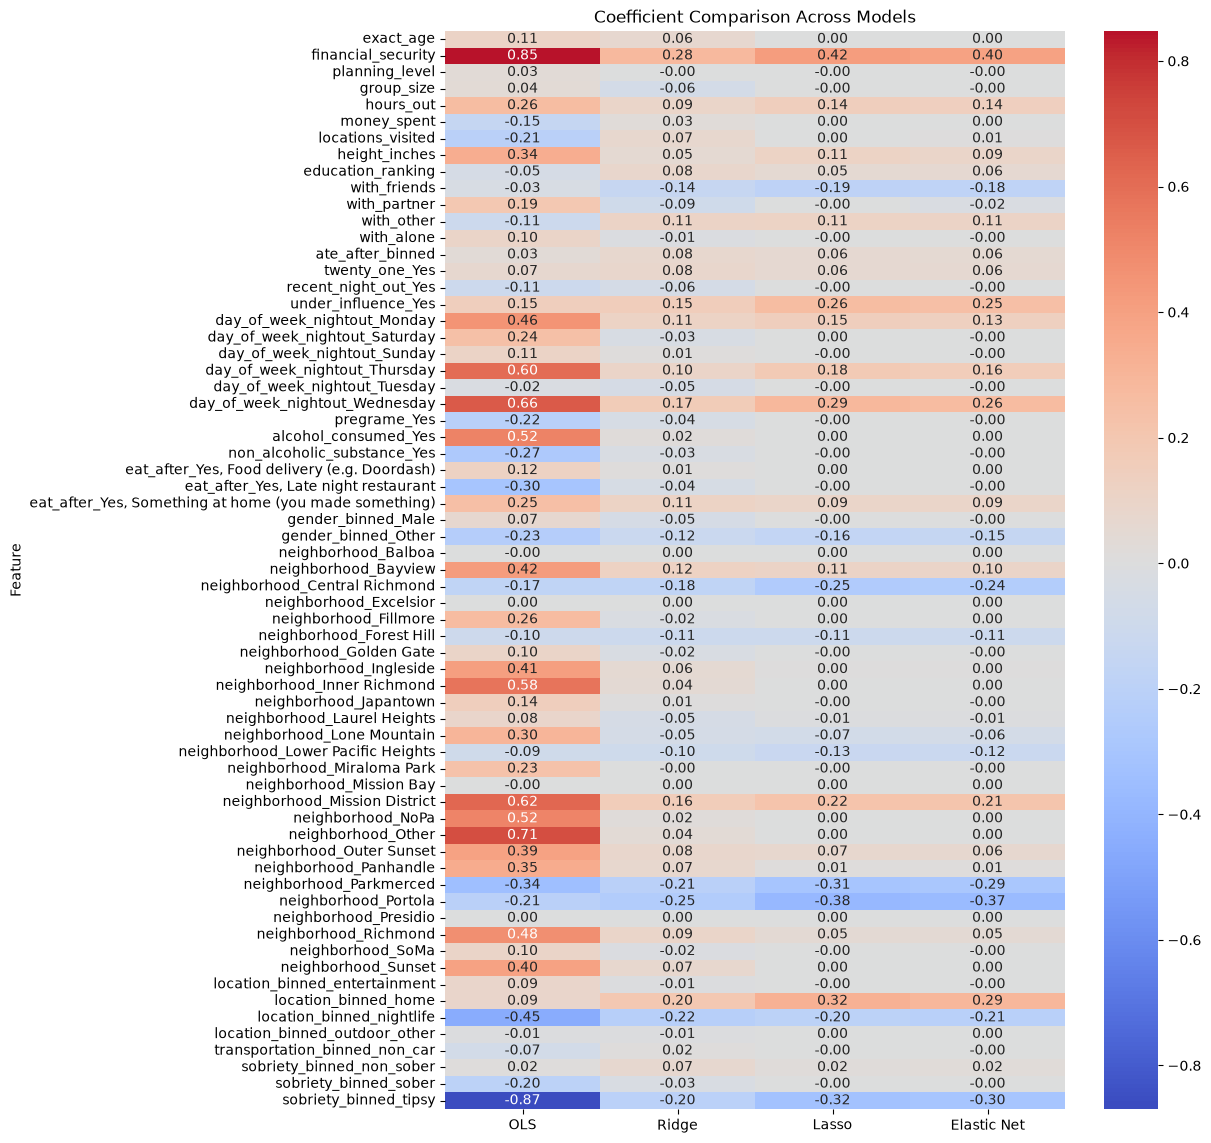

In [231]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 14))

sns.heatmap(
    coefficients.set_index("Feature"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Coefficient Comparison Across Models")
plt.show()

In [232]:
ols_pred = ols.predict(X_test_scaled)
ridge_pred = ridge.predict(X_test_scaled)
lasso_pred = lasso.predict(X_test_scaled)
elastic_pred = elastic.predict(X_test_scaled)

In [233]:
ols_residuals = y_test - ols_pred
ridge_residuals = y_test - ridge_pred
lasso_residuals = y_test - lasso_pred
elastic_residuals = y_test - elastic_pred

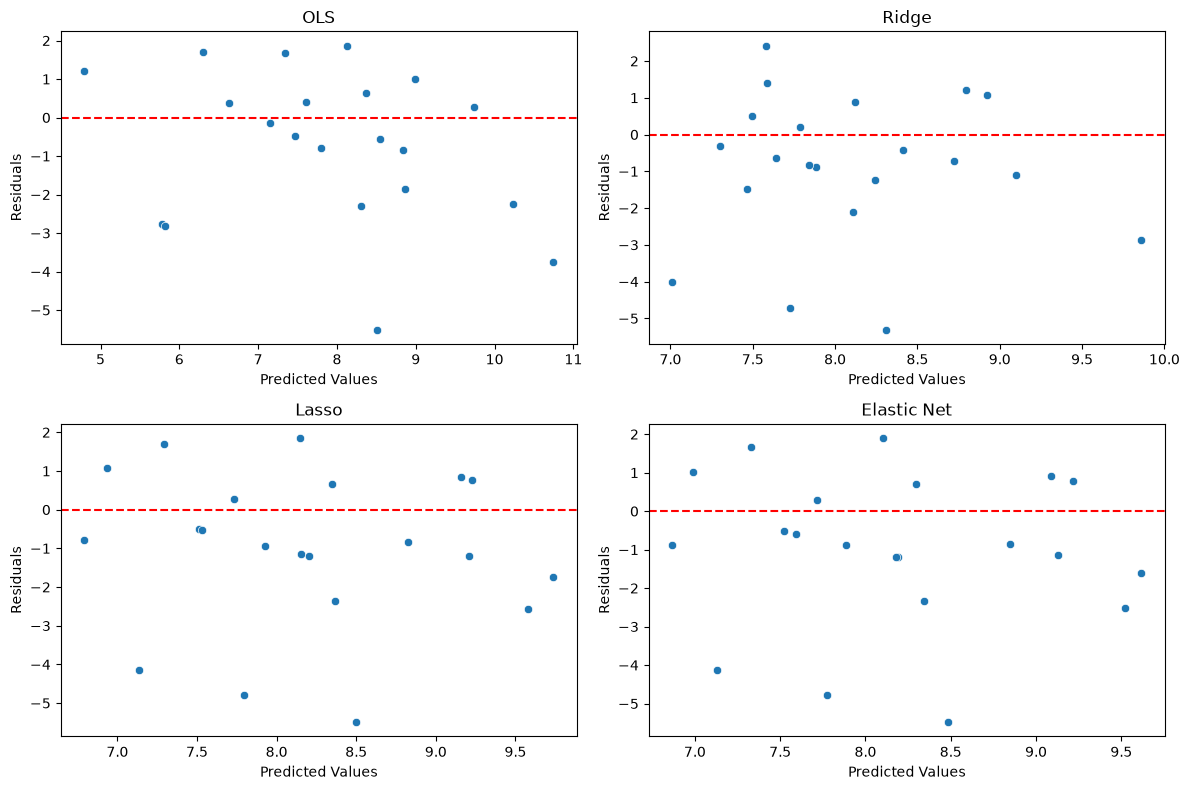

In [234]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

predictions = {
    "OLS": ols_pred,
    "Ridge": ridge_pred,
    "Lasso": lasso_pred,
    "Elastic Net": elastic_pred
}

for i, (name, pred) in enumerate(predictions.items(), 1):

    residuals = y_test - pred

    plt.subplot(2, 2, i)

    sns.scatterplot(x=pred, y=residuals)

    plt.axhline(y=0, color="red", linestyle="--")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")
    plt.title(name)

plt.tight_layout()
plt.show()

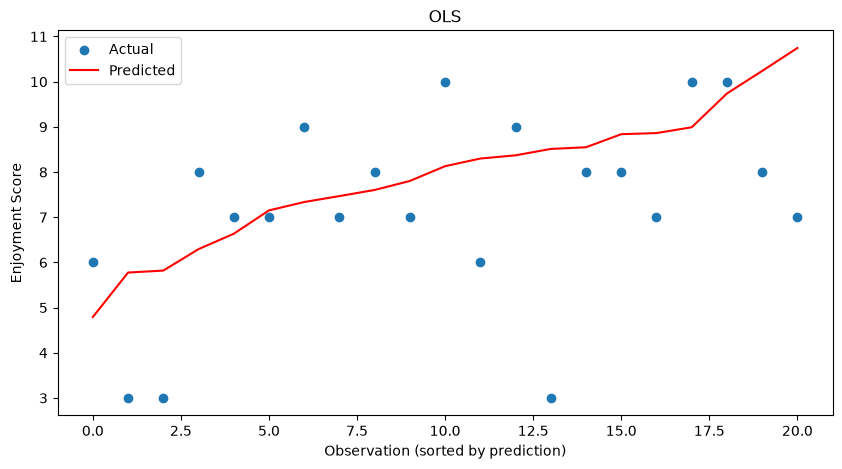

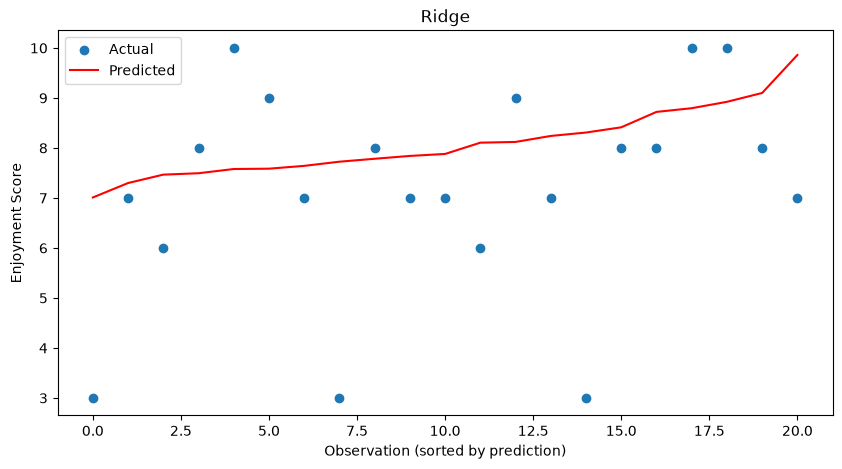

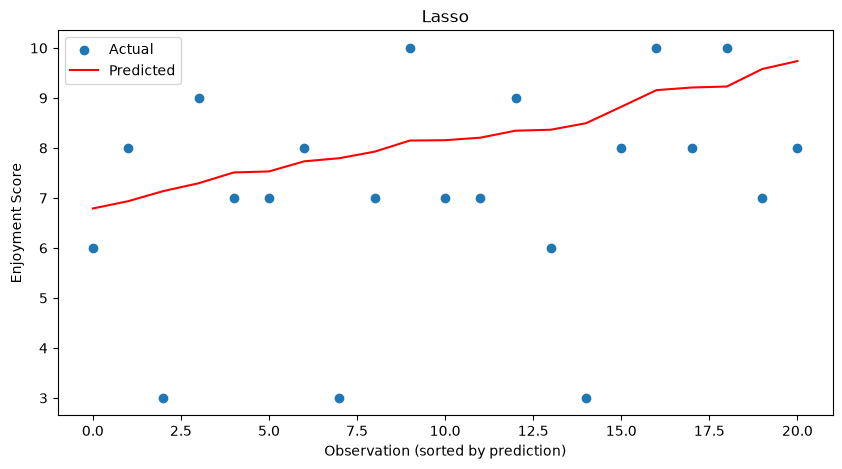

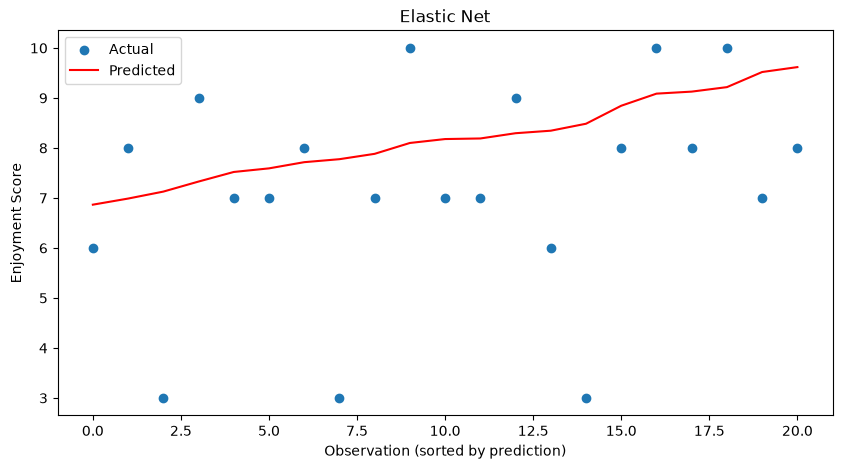

In [235]:
import matplotlib.pyplot as plt
import numpy as np

models = {
    "OLS": ols,
    "Ridge": ridge,
    "Lasso": lasso,
    "Elastic Net": elastic
}

for name, model in models.items():

    # Generate predictions
    y_pred = model.predict(X_test_scaled)

    # Sort observations by predicted enjoyment
    order = np.argsort(y_pred)

    predicted = y_pred[order]
    actual = y_test.to_numpy()[order]

    plt.figure(figsize=(10, 5))

    # Actual observations
    plt.scatter(range(len(actual)), actual, label="Actual")

    # Predicted values
    plt.plot(predicted, color="red", label="Predicted")

    plt.xlabel("Observation (sorted by prediction)")
    plt.ylabel("Enjoyment Score")
    plt.title(name)
    plt.legend()
    plt.show()